# YAGO3-10 — exploratory data analysis


In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from IPython.display import display

SEED = 42
TOP_K = 15
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_columns', 15)


In [2]:
DATASET = 'YAGO3-10'
FILE_NAME = 'yago3-10_train.csv'
candidates = [Path.cwd() / 'data', Path.cwd()]
DATA_DIR = next((p for p in candidates if (p / FILE_NAME).is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError(f'{FILE_NAME} not found. Run from the repository root or data/ directory.')
path = DATA_DIR / FILE_NAME

def read_triples(path):
    options = dict(dtype='string', keep_default_na=False, on_bad_lines='error')
    if path.suffix == '.tsv':
        return pd.read_csv(path, sep='\t', header=None,
                           names=['head', 'relation', 'tail'], **options)
    return pd.read_csv(path, **options)

raw = read_triples(path)
assert list(raw.columns) == ['head', 'relation', 'tail'], raw.columns.tolist()
digest = hashlib.sha256(path.read_bytes()).hexdigest()
display(pd.Series({'file': path.name, 'size_MiB': path.stat().st_size / 2**20,
                   'SHA256': digest, 'rows': len(raw)}, name='source').to_frame())
display(raw.head(8))
display(raw.dtypes.to_frame('dtype'))


,source
file,yago3-10_train.csv
size_MiB,48.933744
SHA256,766918ef5d16eba8344eb99e604321ba04f9b92a3091f5f1874dc54b434920e0
rows,1079040


,head,relation,tail
0,Chatou,isLocatedIn,France
1,Boo_Young-tae,playsFor,Yangju_Citizen_FC
2,Toni_Kuivasto,isAffiliatedTo,Helsingin_Jalkapalloklubi
3,Josh_Smith_(soccer),playsFor,Trinity_University_(Texas)
4,Albrecht_Dürer,diedIn,Nuremberg
5,Edwin_Holliday,isAffiliatedTo,Hereford_United_F.C.
6,William_Hopper,actedIn,The_Bad_Seed_(1956_film)
7,Eric_Maskin,graduatedFrom,Harvard_University


,dtype
head,string
relation,string
tail,string


## 1. Data quality checks


In [3]:
missing = raw.isna()
blank = raw.apply(lambda col: col.str.strip().eq('').fillna(False))
padded = raw.apply(lambda col: col.ne(col.str.strip()).fillna(False))
display(pd.DataFrame({'missing': missing.sum(), 'empty_or_whitespace': blank.sum(),
                      'leading_or_trailing_whitespace': padded.sum()}))
valid_mask = ~(missing | blank).any(axis=1)
valid = raw.loc[valid_mask].copy()
duplicate_count = int(valid.duplicated().sum())
df = valid.drop_duplicates().reset_index(drop=True)
assert not df.empty, 'No valid triples available for analysis.'
quality = pd.Series({'raw_rows': len(raw), 'invalid_rows': int((~valid_mask).sum()),
                     'redundant_duplicates': duplicate_count, 'unique_valid_triples': len(df),
                     'self_loops': int(df['head'].eq(df['tail']).sum())}, name='count')
display(quality.to_frame())
display(df.loc[df['head'].eq(df['tail'])].head(5))


,missing,empty_or_whitespace,leading_or_trailing_whitespace
head,0,0,0
relation,0,0,0
tail,0,0,0


,count
raw_rows,1079040
invalid_rows,0
redundant_duplicates,0
unique_valid_triples,1079040
self_loops,0


,head,relation,tail


## 2. Graph statistics


In [4]:
entities = pd.Index(pd.unique(pd.concat([df['head'], df['tail']], ignore_index=True)), name='entity')
relations = pd.Index(sorted(df['relation'].unique()), name='relation')
n, m, r = len(entities), len(df), len(relations)
heads, tails = set(df['head']), set(df['tail'])
out_degree = df.groupby('head').size().reindex(entities, fill_value=0)
in_degree = df.groupby('tail').size().reindex(entities, fill_value=0)
entity_stats = pd.DataFrame({'in_degree': in_degree, 'out_degree': out_degree})
entity_stats['degree'] = in_degree + out_degree
entity_stats['out_relations'] = df.groupby('head')['relation'].nunique().reindex(entities, fill_value=0)
entity_stats['in_relations'] = df.groupby('tail')['relation'].nunique().reindex(entities, fill_value=0)
entity_stats['role_relations'] = entity_stats['out_relations'] + entity_stats['in_relations']
directed_pairs = df[['head', 'tail']].drop_duplicates()
nonloop_pairs = directed_pairs.loc[directed_pairs['head'].ne(directed_pairs['tail'])]
summary = pd.Series({'triples': m, 'entities': n, 'relations': r,
                     'unique_directed_pairs': len(directed_pairs),
                     'density_without_self_loops': len(nonloop_pairs) / (n * (n - 1)) if n > 1 else np.nan,
                     'head_only': len(heads - tails), 'tail_only': len(tails - heads),
                     'both_roles': len(heads & tails), 'triples_per_entity': m / n}, name=DATASET)
display(summary.to_frame())
display(entity_stats.describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(2))
assert entity_stats['in_degree'].sum() == entity_stats['out_degree'].sum() == m
assert entity_stats['degree'].sum() == 2 * m


,YAGO3-10
triples,1.079040e+06
entities,1.231430e+05
relations,3.700000e+01
unique_directed_pairs,7.926040e+05
density_without_self_loops,5.226853e-05
head_only,7.521000e+04
tail_only,1.029000e+04
both_roles,3.764300e+04
triples_per_entity,8.762496e+00


,in_degree,out_degree,degree,out_relations,in_relations,role_relations
count,123143.00,123143.00,123143.00,123143.00,123143.00,123143.00
mean,8.76,8.76,17.52,2.49,0.70,3.18
std,183.73,8.71,183.81,1.65,1.11,1.53
min,0.00,0.00,1.00,0.00,0.00,1.00
10%,0.00,1.00,3.00,1.00,0.00,1.00
25%,0.00,2.00,5.00,1.00,0.00,2.00
50%,0.00,7.00,10.00,3.00,0.00,3.00
75%,3.00,14.00,16.00,4.00,1.00,4.00
90%,10.00,20.00,24.00,4.00,2.00,5.00
99%,173.00,32.00,181.58,7.00,5.00,8.00


## 3. Relation frequency distribution


,value
top_1_share,0.346403
top_5_share,0.829089
top_10_share,0.929397
entropy_bits,2.896520
normalized_entropy,0.556012
effective_number_of_relations,7.446279


,triples,share,cumulative_share
relation,,,
isAffiliatedTo,373783,0.346403,0.346403
playsFor,321024,0.297509,0.643912
isLocatedIn,88672,0.082177,0.726089
hasGender,66163,0.061317,0.787405
wasBornIn,44978,0.041683,0.829089
actedIn,32155,0.0298,0.858888
isConnectedTo,32055,0.029707,0.888595
hasWonPrize,24068,0.022305,0.9109
influences,10710,0.009925,0.920826


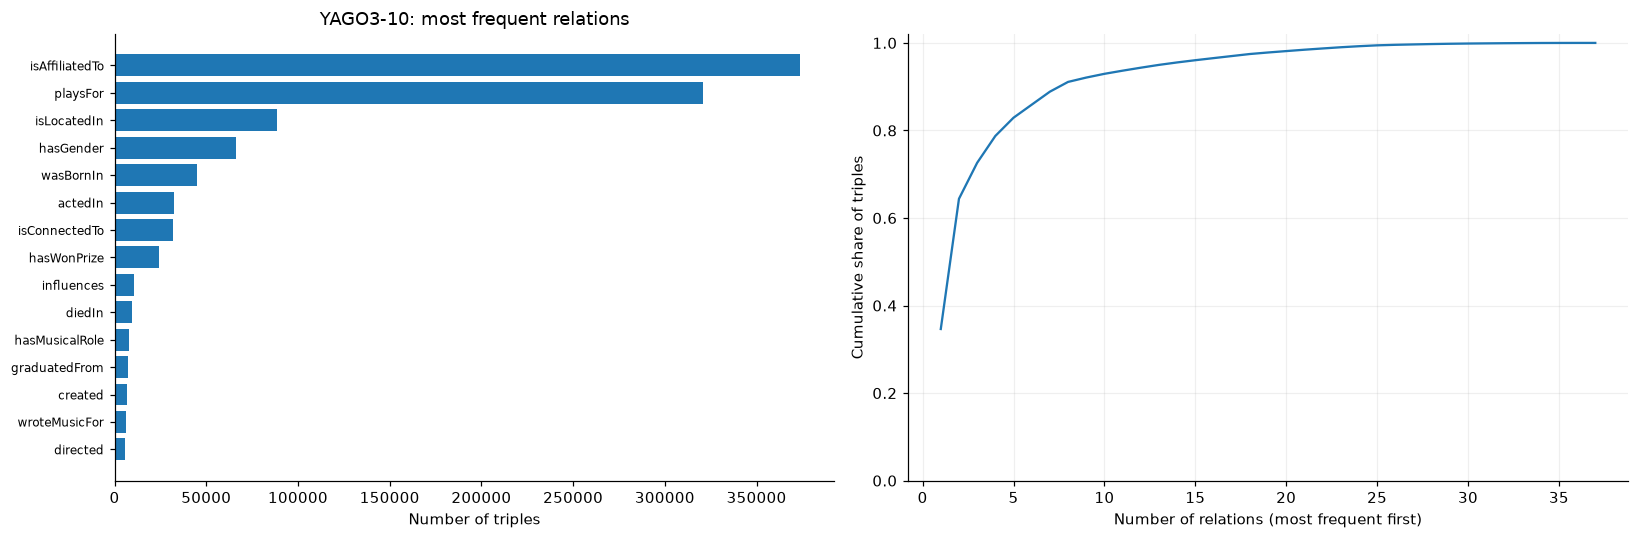

In [5]:
relation_counts = df['relation'].value_counts()
relation_share = relation_counts / m
entropy = float(-(relation_share * np.log2(relation_share)).sum())
relation_balance = pd.Series({'top_1_share': relation_share.iloc[0],
                              'top_5_share': relation_share.head(5).sum(),
                              'top_10_share': relation_share.head(10).sum(),
                              'entropy_bits': entropy,
                              'normalized_entropy': entropy / np.log2(r) if r > 1 else 0.,
                              'effective_number_of_relations': 2**entropy})
display(relation_balance.to_frame('value'))
display(pd.DataFrame({'triples': relation_counts, 'share': relation_share,
                      'cumulative_share': relation_share.cumsum()}).head(20))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
labels = [str(x) if len(str(x)) <= 65 else '…' + str(x)[-64:] for x in relation_counts.head(TOP_K).index]
axes[0].barh(range(len(labels)), relation_counts.head(TOP_K).values)
axes[0].set_yticks(range(len(labels)), labels=labels, fontsize=8)
axes[0].invert_yaxis()
axes[0].set(xlabel='Number of triples', title=f'{DATASET}: most frequent relations')
axes[1].plot(np.arange(1, r + 1), relation_share.cumsum().values)
axes[1].set(xlabel='Number of relations (most frequent first)', ylabel='Cumulative share of triples', ylim=(0, 1.02))
axes[1].grid(alpha=.2)
plt.tight_layout()
plt.show()


## 4. Entity degree distribution and relation diversity


,value
degree_1_entities,4269.000000
degree_le_5_share,0.255695
degree_share_of_top_1pct_entities,0.251192
median_role_relation_count,3.000000


,in_degree,out_degree,degree,out_relations,in_relations,role_relations
entity,,,,,,
male,61044,0,61044,0,1,1
United_States,12206,210,12416,7,8,15
female,5119,0,5119,0,1,1
United_Kingdom,1723,161,1884,8,6,14
London,1729,5,1734,1,8,9
wordnet_guitar_103467517,1660,0,1660,0,1,1
France,1559,85,1644,9,8,17
New_York_City,1429,9,1438,2,7,9
Birmingham_City_F.C.,1367,1,1368,1,2,3


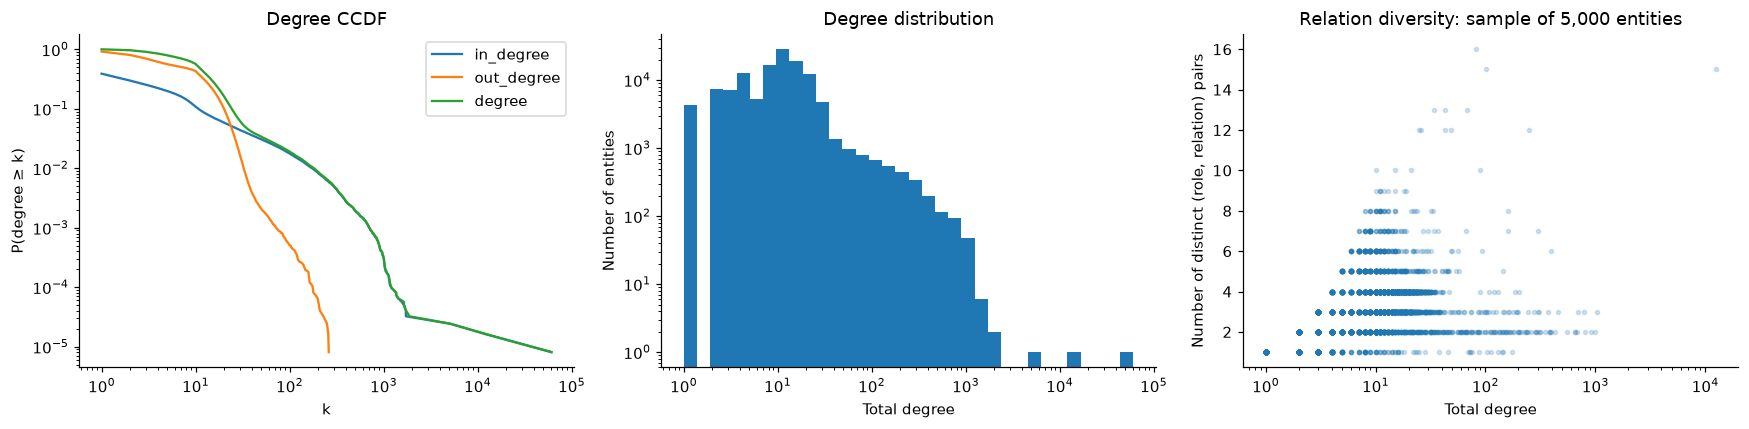

In [6]:
degree = entity_stats['degree']
top_n = max(1, int(np.ceil(.01 * n)))
hub_share = degree.nlargest(top_n).sum() / degree.sum()
display(pd.Series({'degree_1_entities': int(degree.eq(1).sum()),
                   'degree_le_5_share': degree.le(5).mean(),
                   'degree_share_of_top_1pct_entities': hub_share,
                   'median_role_relation_count': entity_stats['role_relations'].median()}).to_frame('value'))
display(entity_stats.sort_values('degree', ascending=False).head(15))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for col in ['in_degree', 'out_degree', 'degree']:
    positive = entity_stats[col].loc[lambda x: x > 0]
    counts = positive.value_counts().sort_index()
    ccdf = counts.iloc[::-1].cumsum().iloc[::-1] / n
    axes[0].plot(counts.index, ccdf, label=col)
axes[0].set(xscale='log', yscale='log', xlabel='k', ylabel='P(degree ≥ k)', title='Degree CCDF')
axes[0].legend()
bins = np.unique(np.geomspace(1, max(2, degree.max()), 35))
axes[1].hist(degree, bins=bins)
axes[1].set(xscale='log', yscale='log', xlabel='Total degree', ylabel='Number of entities', title='Degree distribution')
sample = entity_stats.sample(n=min(5000, n), random_state=SEED)
axes[2].scatter(sample['degree'], sample['role_relations'], s=7, alpha=.2)
axes[2].set(xscale='log', xlabel='Total degree', ylabel='Number of distinct (role, relation) pairs',
            title=f'Relation diversity: sample of {len(sample):,} entities')
plt.tight_layout()
plt.show()


## 5. Connected components


In [7]:
h_codes = entities.get_indexer(df['head'])
t_codes = entities.get_indexer(df['tail'])
adjacency = sparse.coo_matrix((np.ones(m, dtype=np.int64), (h_codes, t_codes)), shape=(n, n)).tocsr()
adjacency.data[:] = 1
weak_n, weak_labels = connected_components(adjacency, directed=True, connection='weak')
strong_n, strong_labels = connected_components(adjacency, directed=True, connection='strong')
weak_sizes = pd.Series(np.bincount(weak_labels)).sort_values(ascending=False)
strong_sizes = pd.Series(np.bincount(strong_labels)).sort_values(ascending=False)
display(pd.DataFrame({'component_count': [weak_n, strong_n],
                      'largest_component': [weak_sizes.iloc[0], strong_sizes.iloc[0]],
                      'largest_component_share': [weak_sizes.iloc[0] / n, strong_sizes.iloc[0] / n],
                      'singleton_components': [(weak_sizes == 1).sum(), (strong_sizes == 1).sum()]},
                     index=['weak', 'strong']))
display(weak_sizes.head(10).rename('entity_count').to_frame().rename_axis('weak_component_id'))


,component_count,largest_component,largest_component_share,singleton_components
weak,12,123111,0.999740,0
strong,111006,7006,0.056893,107799


,entity_count
weak_component_id,
0,123111
2,7
1,4
3,3
7,3
6,3
5,2
4,2
8,2


## 6. Relation cardinality


,triples,heads,tails,tph,hpt,cardinality,head_tail_jaccard
relation,,,,,,,
isAffiliatedTo,373783,48208,10882,7.754,34.349,N–N,0.001
playsFor,321024,45797,8470,7.010,37.901,N–N,0.000
isLocatedIn,88672,39689,13272,2.234,6.681,N–N,0.304
hasGender,66163,66163,2,1.000,33081.500,N–1,0.000
wasBornIn,44978,44978,6081,1.000,7.396,N–1,0.000
actedIn,32155,5403,6754,5.951,4.761,N–N,0.000
isConnectedTo,32055,1497,1892,21.413,16.942,N–N,0.770
hasWonPrize,24068,9232,1051,2.607,22.900,N–N,0.000
influences,10710,2197,2628,4.875,4.075,N–N,0.437


,relations,triples,triple_share
cardinality,,,
1–1,2,6323,0.005860
1–N,5,15356,0.014231
N–1,10,127635,0.118286
N–N,20,929726,0.861623


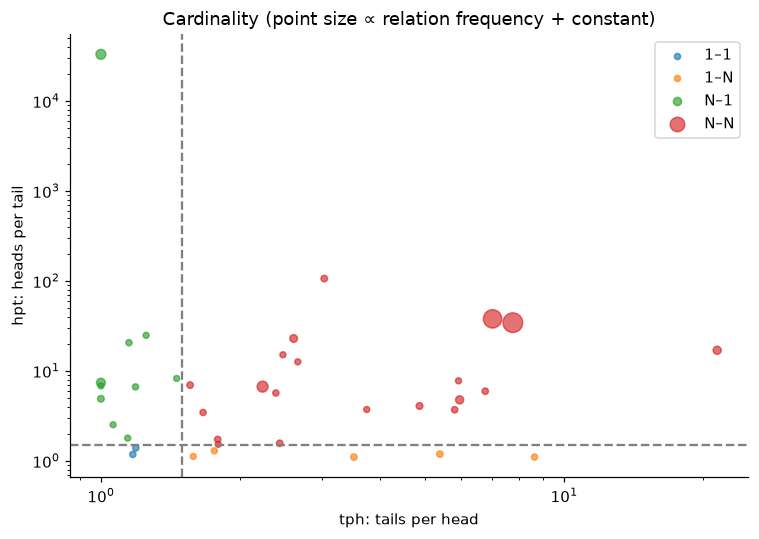

In [8]:
# tph: tails per head; hpt: heads per tail. Cardinality threshold: 1.5.
relation_stats = df.groupby('relation').agg(triples=('head', 'size'),
                                           heads=('head', 'nunique'), tails=('tail', 'nunique'))
relation_stats['tph'] = relation_stats['triples'] / relation_stats['heads']
relation_stats['hpt'] = relation_stats['triples'] / relation_stats['tails']
relation_stats['cardinality'] = np.select(
    [(relation_stats['tph'] < 1.5) & (relation_stats['hpt'] < 1.5),
     (relation_stats['tph'] >= 1.5) & (relation_stats['hpt'] < 1.5),
     (relation_stats['tph'] < 1.5) & (relation_stats['hpt'] >= 1.5)],
    ['1–1', '1–N', 'N–1'], default='N–N')
head_sets = {rel: set(group['head']) for rel, group in df.groupby('relation')}
tail_sets = {rel: set(group['tail']) for rel, group in df.groupby('relation')}
relation_stats['head_tail_jaccard'] = [len(head_sets[x] & tail_sets[x]) / len(head_sets[x] | tail_sets[x])
                                       for x in relation_stats.index]
display(relation_stats.sort_values('triples', ascending=False).head(20).round(3))
cardinality_summary = relation_stats.groupby('cardinality').agg(relations=('triples', 'size'), triples=('triples', 'sum'))
cardinality_summary['triple_share'] = cardinality_summary['triples'] / m
display(cardinality_summary)
fig, ax = plt.subplots(figsize=(7, 5))
for category, group in relation_stats.groupby('cardinality'):
    ax.scatter(group['tph'], group['hpt'], s=15 + 150 * group['triples'] / relation_stats['triples'].max(),
               alpha=.65, label=category)
ax.axvline(1.5, linestyle='--', color='grey')
ax.axhline(1.5, linestyle='--', color='grey')
ax.set(xscale='log', yscale='log', xlabel='tph: tails per head', ylabel='hpt: heads per tail',
       title='Cardinality (point size ∝ relation frequency + constant)')
ax.legend()
plt.tight_layout()
plt.show()


## 7. Similarity of relation participant sets


,id,relation
0,R1,isAffiliatedTo
1,R2,playsFor
2,R3,isLocatedIn
3,R4,hasGender
4,R5,wasBornIn
5,R6,actedIn
6,R7,isConnectedTo
7,R8,hasWonPrize
8,R9,influences
9,R10,diedIn


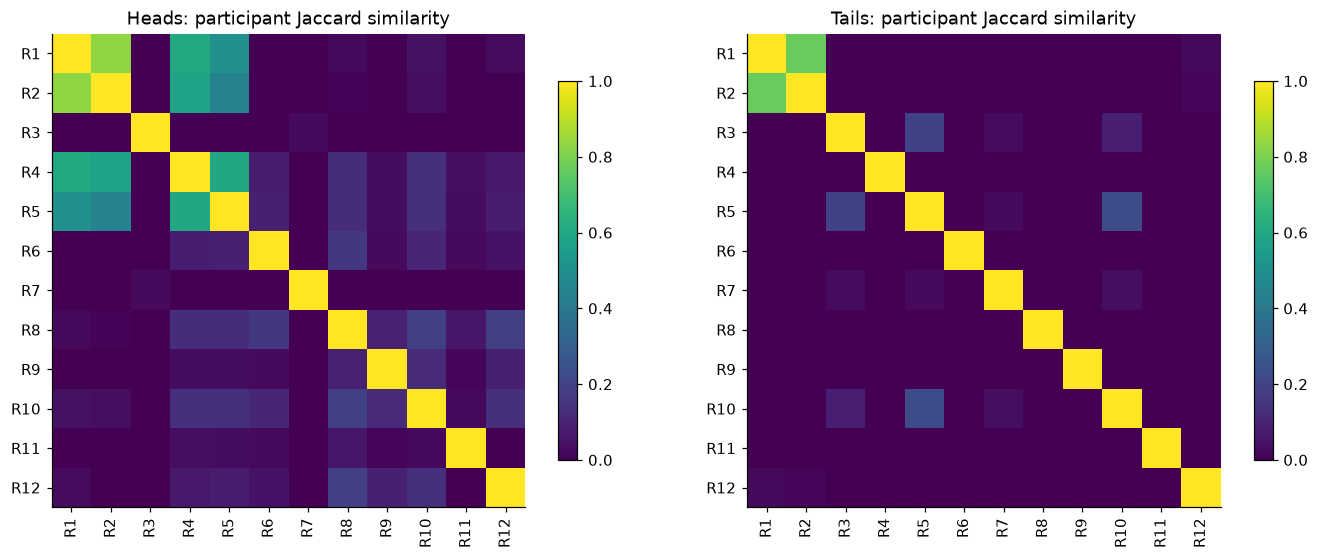

,relation_A,relation_B,head_jaccard,tail_jaccard
0,isAffiliatedTo,playsFor,0.835,0.766
2,isAffiliatedTo,hasGender,0.608,0.000
30,hasGender,wasBornIn,0.598,0.000
12,playsFor,hasGender,0.580,0.000
3,isAffiliatedTo,wasBornIn,0.508,0.000
13,playsFor,wasBornIn,0.442,0.000
57,hasWonPrize,diedIn,0.189,0.000
59,hasWonPrize,graduatedFrom,0.189,0.000
46,actedIn,hasWonPrize,0.163,0.000
42,wasBornIn,diedIn,0.136,0.232


In [9]:
selected_relations = relation_counts.head(12).index.tolist()
relation_key = pd.DataFrame({'id': [f'R{i+1}' for i in range(len(selected_relations))],
                             'relation': selected_relations})
display(relation_key)
def jaccard_matrix(sets, names):
    return np.array([[len(sets[a] & sets[b]) / len(sets[a] | sets[b]) for b in names] for a in names])
head_overlap = jaccard_matrix(head_sets, selected_relations)
tail_overlap = jaccard_matrix(tail_sets, selected_relations)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, matrix, label in zip(axes, [head_overlap, tail_overlap], ['Heads', 'Tails']):
    im = ax.imshow(matrix, vmin=0, vmax=1, cmap='viridis')
    ax.set_xticks(range(len(relation_key)), labels=relation_key['id'], rotation=90)
    ax.set_yticks(range(len(relation_key)), labels=relation_key['id'])
    ax.set_title(f'{label}: participant Jaccard similarity')
    fig.colorbar(im, ax=ax, shrink=.8)
plt.tight_layout()
plt.show()
overlap_pairs = pd.DataFrame([
    {'relation_A': a, 'relation_B': b, 'head_jaccard': head_overlap[i, j],
     'tail_jaccard': tail_overlap[i, j]}
    for i, a in enumerate(selected_relations) for j, b in enumerate(selected_relations) if i < j])
display(overlap_pairs.sort_values(['head_jaccard', 'tail_jaccard'], ascending=False).head(10).round(3))


## 8. Reverse pairs


In [10]:
# Exclude self-loops to avoid inflating the share of reverse pairs.
pair_sets = {rel: set(group.loc[group['head'].ne(group['tail']), ['head', 'tail']].itertuples(index=False, name=None))
             for rel, group in df.groupby('relation')}
same_reverse = []
for rel, pairs in pair_sets.items():
    matched = sum((t, h) in pairs for h, t in pairs)
    same_reverse.append({'relation': rel, 'nonloop_pairs': len(pairs), 'reverse_pairs': matched,
                         'reverse_share': matched / len(pairs) if pairs else np.nan})
same_reverse = pd.DataFrame(same_reverse).sort_values(['reverse_share', 'nonloop_pairs'], ascending=False)
display(same_reverse.head(15))
inverse_rows = []
for rel in selected_relations:
    pairs = pair_sets[rel]
    reverse = {(t, h) for h, t in pairs}
    options = [(len(reverse & pair_sets[other]), other) for other in selected_relations if other != rel]
    if options:
        support, other = max(options)
        inverse_rows.append({'relation': rel, 'best_reverse_relation_in_top12': other,
                             'matched_pairs': support, 'source_pairs': len(pairs),
                             'coverage': support / len(pairs) if pairs else np.nan})
inverse_table = pd.DataFrame(inverse_rows).sort_values('coverage', ascending=False)
display(inverse_table.round(4))


,relation,nonloop_pairs,reverse_pairs,reverse_share
15,hasNeighbor,555,550,0.990991
28,isMarriedTo,3757,3674,0.977908
23,isConnectedTo,32055,21236,0.662486
25,isKnownFor,19,4,0.210526
2,dealsWith,1302,160,0.122888
11,hasChild,5064,414,0.081754
27,isLocatedIn,88672,5742,0.064756
20,influences,10710,180,0.016807
31,owns,726,4,0.005510
9,hasAcademicAdvisor,914,4,0.004376


,relation,best_reverse_relation_in_top12,matched_pairs,source_pairs,coverage
6,isConnectedTo,isLocatedIn,1,32055,0.0
2,isLocatedIn,isConnectedTo,1,88672,0.0
1,playsFor,wasBornIn,0,321024,0.0
0,isAffiliatedTo,wasBornIn,0,373783,0.0
3,hasGender,wasBornIn,0,66163,0.0
4,wasBornIn,playsFor,0,44978,0.0
5,actedIn,wasBornIn,0,32155,0.0
7,hasWonPrize,wasBornIn,0,24068,0.0
8,influences,wasBornIn,0,10710,0.0
9,diedIn,wasBornIn,0,9248,0.0


## 9. Relational profiles and entity similarity


In [11]:
rel_codes = relations.get_indexer(df['relation'])
profile = sparse.coo_matrix((np.ones(2*m, dtype=np.int64),
                             (np.concatenate([h_codes, t_codes]),
                              np.concatenate([rel_codes, r + rel_codes]))), shape=(n, 2*r)).tocsr()
profile.sum_duplicates()
profile.data[:] = 1
signatures = [tuple(profile.indices[profile.indptr[i]:profile.indptr[i+1]]) for i in range(n)]
signature_series = pd.Series(signatures, index=entities, name='signature')
signature_counts = signature_series.value_counts()
multiplicity = signature_series.map(signature_counts)
collision_share = float(multiplicity.gt(1).mean())
assert profile.sum() == entity_stats['role_relations'].sum()
display(pd.Series({'distinct_profiles': len(signature_counts),
                   'unique_profile_entity_share': multiplicity.eq(1).mean(),
                   'shared_profile_entity_share': collision_share,
                   'largest_identical_profile_group': signature_counts.iloc[0]}).to_frame('value'))
feature_names = [('out: ' if i < r else 'in: ') + str(relations[i % r]) for i in range(2*r)]
common_profiles = []
for signature, count in signature_counts.head(8).items():
    example_entities = signature_series.index[signature_series == signature].tolist()[:5]
    common_profiles.append({'entity_count': count, 'profile': [feature_names[j] for j in signature],
                            'example_entities': example_entities})
display(pd.DataFrame(common_profiles))
q1, q3 = degree.quantile([.25, .75])
pool = entity_stats.loc[degree.between(q1, q3)]
query = pool['role_relations'].idxmax()
query_index = entities.get_loc(query)
intersections = (profile @ profile[query_index].T).toarray().ravel()
profile_sizes = np.asarray(profile.sum(axis=1)).ravel()
similarities = intersections / (profile_sizes + profile_sizes[query_index] - intersections)
similarities[query_index] = -1
display(pd.Series({'query_entity': query, 'degree': degree.loc[query],
                   'profile': [feature_names[j] for j in signatures[query_index]]}).to_frame('value'))
nearest = np.argsort(-similarities, kind='stable')[:10]
neighbors = entity_stats.iloc[nearest].copy()
neighbors['profile_jaccard'] = similarities[nearest]
display(neighbors)


,value
distinct_profiles,4646.000000
unique_profile_entity_share,0.021154
shared_profile_entity_share,0.978846
largest_identical_profile_group,23277.000000


,entity_count,profile,example_entities
0,23277,"[out: hasGender, out: isAffiliatedTo, out: playsFor, out: wasBornIn]","[Toni_Kuivasto, Josh_Smith_(soccer), Edwin_Holliday, Benedict_Iroha, Ariel_Garcé]"
1,12971,"[out: hasGender, out: isAffiliatedTo, out: playsFor]","[George_Mallia, Héctor_Cúper, Trevor_Senior, Simone_Zaza, László_Sternberg]"
2,10717,[out: isLocatedIn],"[Chatou, Bruce_County, Gmina_Widawa, Remington_Arms, Gmina_Osiek,_Kuyavian-Pomeranian_Voivodeship]"
3,6411,"[in: isAffiliatedTo, in: playsFor]","[Yangju_Citizen_FC, Malta_national_football_team, Rosario_Central, Dorchester_Town_F.C., Maccles..."
4,6324,"[out: isLocatedIn, in: isLocatedIn]","[Bangalore_Urban_district, Súdwest-Fryslân, Maiquetía, Vrbas,_Serbia, Frances_Baard_District_Mun..."
5,2685,"[out: isAffiliatedTo, out: playsFor, out: wasBornIn]","[Peter_Creamer, Eric_Rapo, Marcelo_Goianira, Stephan_Marasek, Bogdan_Străuț]"
6,2132,"[out: isLocatedIn, in: wasBornIn]","[Randers, Ashland,_Kentucky, Lockport_(city),_New_York, Hopedale,_Massachusetts, Płońsk]"
7,2073,"[out: hasGender, out: playsFor]","[Emanuele_Concetti, Richard_Anthony_(politician), Stefano_Bono, Gilbert_Dean, Francesco_Caracciolo]"


,value
query_entity,Irène_Joliot-Curie
degree,16
profile,"[out: diedIn, out: graduatedFrom, out: hasAcademicAdvisor, out: hasGender, out: hasWonPrize, out..."


,in_degree,out_degree,degree,out_relations,in_relations,role_relations,profile_jaccard
entity,,,,,,,
Marshall_Harvey_Stone,1,10,11,8,1,9,0.750000
Eunice_Kennedy_Shriver,3,10,13,10,2,12,0.714286
Pierre_Curie,3,15,18,10,2,12,0.714286
Lynn_Margulis,1,15,16,9,1,10,0.692308
Ra'ana_Liaquat_Ali_Khan,1,11,12,9,1,10,0.692308
Jaroslav_Heyrovský,0,11,11,8,0,8,0.666667
Paul_Halmos,0,13,13,8,0,8,0.666667
Muhammad_Raziuddin_Siddiqui,0,18,18,8,0,8,0.666667
Kenneth_G._Wilson,0,14,14,8,0,8,0.666667


## 10. Availability of type labels


In [12]:
known_type_relations = {'rdf:type', 'type', 'isA', 'isa', 'instanceOf', 'isInstanceOf',
                        '/type/object/type', 'http://www.w3.org/1999/02/22-rdf-syntax-ns#type'}
type_relations = [x for x in relations if str(x) in known_type_relations]
type_rows = df.loc[df['relation'].isin(type_relations)]
display(pd.Series({'recognized_type_predicates': type_relations,
                   'type_triples': len(type_rows),
                   'typed_head_entities': type_rows['head'].nunique(),
                   'entity_coverage': type_rows['head'].nunique() / n}).to_frame('result'))
if not type_rows.empty:
    display(type_rows['tail'].value_counts().head(15).to_frame('type_triple_count'))


,result
recognized_type_predicates,[]
type_triples,0
typed_head_entities,0
entity_coverage,0.0


## 11. Comparison of FB15k-237 and YAGO3-10


,triples,entities,relations,median_degree,degree_le_5_share,top_5_relation_share,effective_relations
file,,,,,,,
fb15k-237_train.tsv,272115,14505,237,22.0,0.1111,0.2259,93.8744
yago3-10_train.csv,1079040,123143,37,10.0,0.2557,0.8291,7.4463


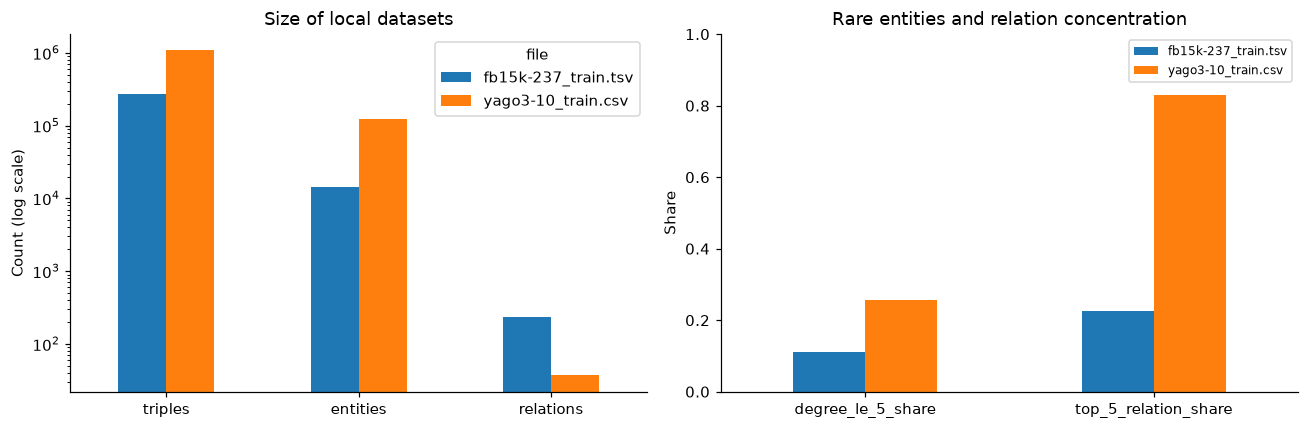

In [13]:
def comparison_row(file_name):
    other_path = DATA_DIR / file_name
    if not other_path.is_file():
        return None
    other = read_triples(other_path)
    ok = ~(other.isna() | other.apply(lambda col: col.str.strip().eq('').fillna(False))).any(axis=1)
    other = other.loc[ok].drop_duplicates()
    other_entities = pd.Index(pd.unique(pd.concat([other['head'], other['tail']], ignore_index=True)))
    other_degree = (other.groupby('head').size().reindex(other_entities, fill_value=0)
                    + other.groupby('tail').size().reindex(other_entities, fill_value=0))
    shares = other['relation'].value_counts(normalize=True)
    return {'file': file_name, 'triples': len(other), 'entities': len(other_entities),
            'relations': other['relation'].nunique(), 'median_degree': other_degree.median(),
            'degree_le_5_share': other_degree.le(5).mean(),
            'top_5_relation_share': shares.head(5).sum(),
            'effective_relations': 2**float(-(shares * np.log2(shares)).sum())}

comparison_rows = [comparison_row(f) for f in ['fb15k-237_train.tsv', 'yago3-10_train.csv']]
comparison = pd.DataFrame([row for row in comparison_rows if row is not None]).set_index('file')
display(comparison.round(4))
if len(comparison) == 2:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    comparison[['triples', 'entities', 'relations']].T.plot.bar(ax=axes[0], logy=True, rot=0)
    axes[0].set(title='Size of local datasets', ylabel='Count (log scale)')
    comparison[['degree_le_5_share', 'top_5_relation_share']].T.plot.bar(ax=axes[1], rot=0)
    axes[1].set(title='Rare entities and relation concentration', ylabel='Share', ylim=(0, 1))
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    plt.show()
